# CMOS sensor: isolating the numerical discrepancy

## Results at a glance

The controlled experiments identified three correctable issues: accumulated float32 monitor time, a biased incident-power denominator, and magnetic-field interpolation across the silicon interface. The solver now uses an integer-step clock; this notebook quantifies the effects of native incident calibration and optional one-sided detector sampling. These corrections do **not** establish agreement with the published Tidy3D sensor.

Planar depth refinement converges to the transfer-matrix solution. Removing lenses and metal structures isolates their contribution within BeamZ, but cannot assign an inter-solver error without matched Tidy3D component data.

This is an executed analysis of saved RTX3090 runs. To repeat the simulations, use the commands in [the evidence report](../../docs/reviews/cmos-isolation/README.md). The [main sensor notebook](cmos_rgb_sensor.ipynb) executes the corrected full-device workflow.

## Context and methods

All runs retain the imported material poles, source polarization, physical detector plane and 3 × 3 µm incident aperture. Full-sensor runs use 20 nm lateral cells, the reconstructed 430-cell reference z mesh, 510 fs and 200 frequencies. Green combines both green apertures.

### Key assumptions

- Native E-plane wave decomposition applies to a normally incident wave in uniform-grid air. It is not a general power estimator for patterned fields.
- One-sided detector sampling extrapolates H from three samples inside SiN to the original silicon interface. The stencil must remain in one smooth region.
- Planar transmission controls retain paired interpolated empty-plane normalization, so their errors include that sampling bias. The full sensor uses native incident calibration; reflection and complex-field checks provide independent evidence.
- Planar transfer matrices provide an independent physical reference. Full-sensor Tidy3D values (~6/20/6% at 650/550/450 nm) are approximate plot readings; numerical reference spectra are unavailable.
- The Tidy3D reference uses roughly 7.7 nm lateral cells and different subpixel operators. The 20 nm sensor is not a common-mesh parity test.

Sources: [published notebook](https://www.flexcompute.com/tidy3d/examples/notebooks/CMOSRGBSensor/), checked-in simulation snapshot, and the raw spectra/report JSON files loaded below.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/"examples/cmos_rgb_sensor.py").exists())
evidence = root/"docs/reviews/cmos-isolation"
historical = root/"docs/reviews/cmos-polarized/reference-z-20nm-absorber"
colors = dict(red="#c43c39",green="#247b4a",blue="#3265b0")
central = dict(red=650,green=550,blue=450)
plt.rcParams.update({"font.size":11,"axes.spines.top":False,"axes.spines.right":False,"figure.figsize":(9,4)})
def read_report(path):
    return json.loads(path.read_text())
def combine(data, channel):
    return data["green1"]+data["green2"] if channel=="green" else data[channel]
def at_center(values, wavelength_nm, channel):
    order=np.argsort(wavelength_nm)
    return 100*np.interp(central[channel],wavelength_nm[order],values[order])
def show_table(labels, rows):
    header="| " + " | ".join(labels) + " |\n|" + "|".join(["---"]*len(labels)) + "|\n"
    display(Markdown(header + "\n".join("| " + " | ".join(map(str,r)) + " |" for r in rows)))
print("Raw inputs:", evidence.relative_to(root))

Raw inputs: docs/reviews/cmos-isolation


## Incident-power calibration

The former denominator was a colocated E × H flux on coarse air cells. The new denominator separates forward and backward waves using two native E planes and the discrete Yee wave number. Both use the complete unit-cell aperture.

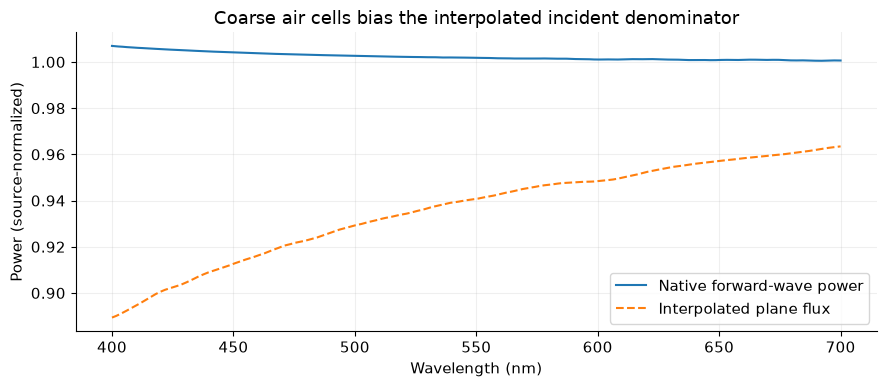

| Wavelength | Old flux / forward power |
|---|---|
| 450 nm | 0.9089 |
| 550 nm | 0.9391 |
| 650 nm | 0.9564 |

Maximum backward power: 0.0024929338759215464


In [2]:
incident=np.load(evidence/"incident/spectra.npz")
wl=incident["wavelength_nm"]
order=np.argsort(wl)
fig, ax=plt.subplots()
ax.plot(wl[order],incident["modal_power"][order],label="Native forward-wave power")
ax.plot(wl[order],incident["plane_power"][order],"--",label="Interpolated plane flux")
ax.set(xlabel="Wavelength (nm)",ylabel="Power (source-normalized)",title="Coarse air cells bias the interpolated incident denominator")
ax.grid(alpha=.2);ax.legend()
fig.tight_layout();fig.savefig(evidence/"incident_calibration.png",dpi=150);plt.show()
show_table(["Wavelength","Old flux / forward power"],[(f"{w} nm",f"{np.interp(w,wl[order],(incident['plane_power']/incident['modal_power'])[order]):.4f}") for w in (450,550,650)])
print("Maximum backward power:",float(incident["backward_power"].max()))

## Planar stack convergence and the clock defect

Each stack has a full-plane RGB filter and the same silica/SiN/silicon layers, with no lenses or metal patterns. Refinement subdivides every original z interval and preserves all original edges. Errors are maxima over 400–700 nm. The clock fix ties Fourier phase to integer timesteps rather than repeatedly adding float32 dt.

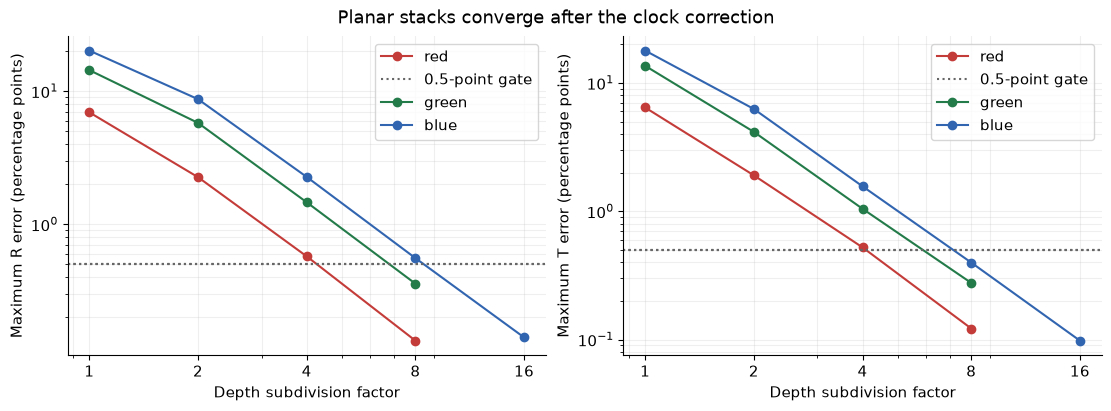

| Channel, depth ×8 | Old-clock T error (pp) | Integer-clock T error (pp) |
|---|---|---|
| red | 1.033 | 0.122 |
| green | 2.318 | 0.276 |
| blue | 3.501 | 0.398 |

| Coarse stack, central wavelength | Transmission phase error (rad) |
|---|---|
| red | 0.425 |
| green | 0.740 |
| blue | 1.350 |

In [3]:
planar=read_report(evidence/"planar/absorber/report.json")["runs"]
old_planar=read_report(evidence/"planar/absorber-accumulated-clock/report.json")["runs"]
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for channel,color in colors.items():
    rows=sorted((r for r in planar if r["channel"]==channel),key=lambda r:r["depth_refinement"])
    factors=[r["depth_refinement"] for r in rows]
    for ax,key in zip(axes,("R","T")):
        error=[r["R_error_pp"] if key=="R" else r["T_error_pp"]["one_sided"] for r in rows]
        ax.loglog(factors,error,"o-",color=color,label=channel)
        ax.set(xlabel="Depth subdivision factor",ylabel=f"Maximum {key} error (percentage points)")
        ax.axhline(.5,color="0.4",ls=":",label="0.5-point gate" if channel=="red" else None)
        ax.grid(alpha=.2,which="both")
        ax.set_xticks([1,2,4,8,16],labels=["1","2","4","8","16"])
axes[0].legend();axes[1].legend()
fig.suptitle("Planar stacks converge after the clock correction")
fig.savefig(evidence/"planar_convergence.png",dpi=150);plt.show()
rows=[]
for channel in colors:
    old=next(r for r in old_planar if r["channel"]==channel and r["depth_refinement"]==8)
    new=next(r for r in planar if r["channel"]==channel and r["depth_refinement"]==8)
    rows.append((channel,f"{old['T_error_pp']['one_sided']:.3f}",f"{new['T_error_pp']['one_sided']:.3f}"))
show_table(["Channel, depth ×8","Old-clock T error (pp)","Integer-clock T error (pp)"],rows)
phase_rows=[]
for channel in colors:
    raw=np.load(evidence/f"planar/absorber/{channel}-refine1.npz")
    phase=float(np.interp(central[channel],raw["wavelength_nm"],np.angle(raw["t"]/raw["t_exact"])))
    phase_rows.append((channel,f"{phase:.3f}"))
show_table(["Coarse stack, central wavelength","Transmission phase error (rad)"],phase_rows)

## Full sensor: separate the corrections

These comparisons retain the same geometry and detector plane. The first correction changes the DFT clock, the second changes only the incident denominator, and the third changes only H colocation. A correction need not move the result toward the published plot to be physically justified.

| Configuration | Red, 650 nm | Green, 550 nm | Blue, 450 nm |
|---|---|---|---|
| Historical | 9.785% | 20.615% | 8.849% |
| Clock corrected | 9.781% | 20.611% | 8.849% |
| + incident calibration | 9.354% | 19.354% | 8.043% |
| + one-sided detector | 9.725% | 20.652% | 9.203% |
| Published plot (approximate) | ~6% | ~20% | ~6% |

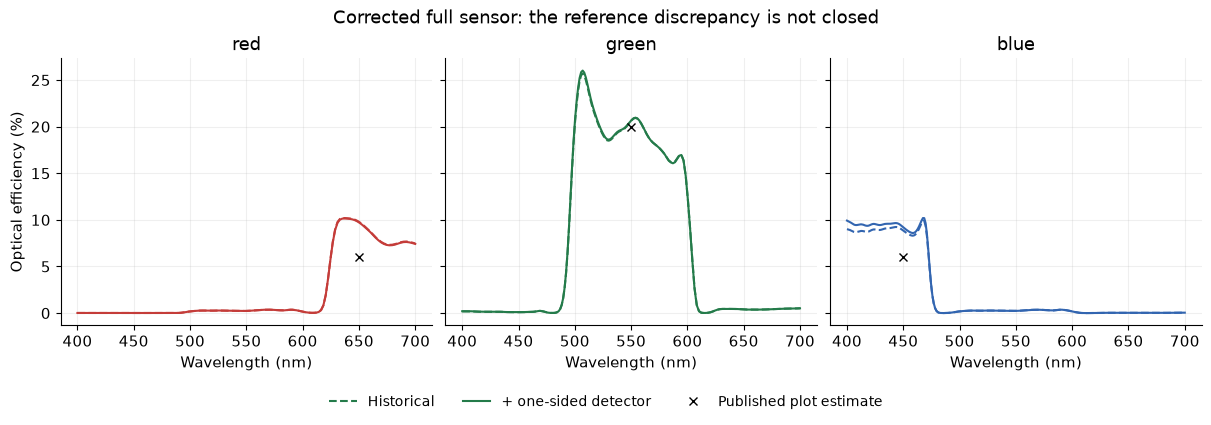

In [4]:
old_raw=np.load(historical/"sensor_spectra.npz")
old_ref=np.load(historical/"reference_spectra.npz")["incident_plane"]
linear_raw=np.load(evidence/"components/full/linear_spectra.npz")
new_raw=np.load(evidence/"components/full/sensor_spectra.npz")
current_ref=np.load(evidence/"components/full/incident_calibration.npz")
curves={"Historical":{},"Clock corrected":{},"+ incident calibration":{},"+ one-sided detector":{}}
for channel in colors:
    curves["Historical"][channel]=combine(old_raw,channel)/old_ref
    curves["Clock corrected"][channel]=combine(linear_raw,channel)/current_ref["plane_power"]
    curves["+ incident calibration"][channel]=combine(linear_raw,channel)/current_ref["modal_power"]
    curves["+ one-sided detector"][channel]=combine(new_raw,channel)/current_ref["modal_power"]
rows=[(label,*[f"{at_center(data[ch],wl,ch):.3f}%" for ch in colors]) for label,data in curves.items()]
rows.append(("Published plot (approximate)","~6%","~20%","~6%"))
show_table(["Configuration","Red, 650 nm","Green, 550 nm","Blue, 450 nm"],rows)
fig,axes=plt.subplots(1,3,figsize=(12,3.7),sharey=True,constrained_layout=True)
for ax,(channel,color) in zip(axes,colors.items()):
    for label,style in (("Historical","--"),("+ one-sided detector","-")):
        ax.plot(wl[order],100*curves[label][channel][order],style,color=color,label=label)
    ax.plot(central[channel],20 if channel=="green" else 6,"kx",label="Published plot estimate")
    ax.set(title=channel,xlabel="Wavelength (nm)")
    ax.grid(alpha=.2)
axes[0].set_ylabel("Optical efficiency (%)");fig.legend(*axes[1].get_legend_handles_labels(),loc="upper center",bbox_to_anchor=(.5,-.02),ncol=3,frameon=False,fontsize=10)
fig.suptitle("Corrected full sensor: the reference discrepancy is not closed")
fig.savefig(evidence/"sensor_corrections.png",dpi=150,bbox_inches="tight");plt.show()

## Component controls

All three stages use the same mesh, source, calibration and detector reconstruction. Differences identify the effects of structures within BeamZ. They do not measure the error in Tidy3D’s handling of those structures.

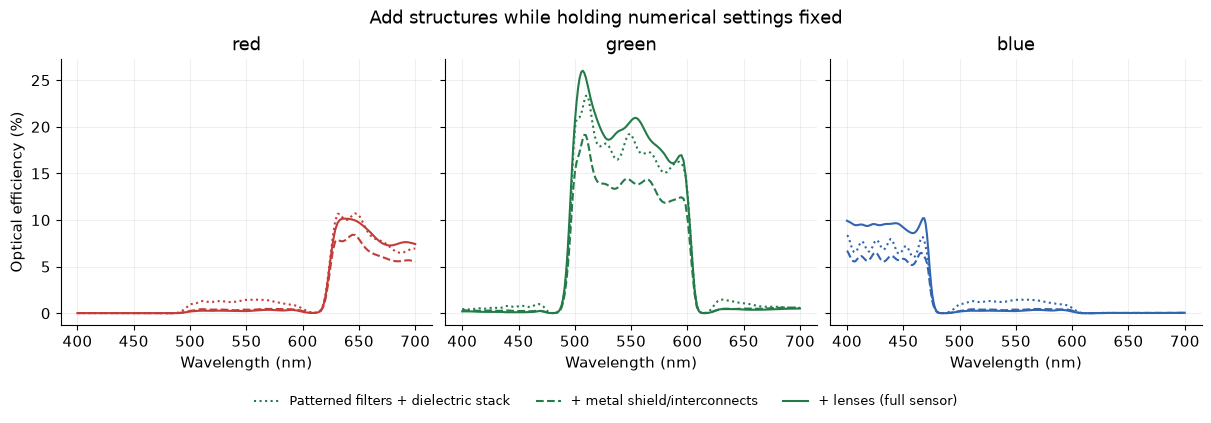

| Stage | Red | Green | Blue | Max 300–510 fs change (pp) |
|---|---|---|---|---|
| Patterned filters + dielectric stack | 10.463% | 19.123% | 6.912% | 0.0095 |
| + metal shield/interconnects | 7.949% | 14.194% | 5.831% | 0.0084 |
| + lenses (full sensor) | 9.725% | 20.652% | 9.203% | 0.0146 |

In [5]:
stages=("bare_stack","no_lenses","full")
labels={"bare_stack":"Patterned filters + dielectric stack","no_lenses":"+ metal shield/interconnects","full":"+ lenses (full sensor)"}
fig,axes=plt.subplots(1,3,figsize=(12,3.7),sharey=True,constrained_layout=True)
rows=[]
for stage,style in zip(stages,(":","--","-")):
    data=np.load(evidence/f"components/{stage}/calibrated_efficiency.npz")
    report=read_report(evidence/f"components/{stage}/report.json")
    rows.append((labels[stage],*[f"{report['central_efficiency_percent'][ch]:.3f}%" for ch in colors],f"{max(report['temporal_max_change_pp'].values()):.4f}"))
    for ax,(channel,color) in zip(axes,colors.items()):
        ax.plot(wl[order],100*data[channel][order],style,color=color,label=labels[stage])
        ax.set(title=channel,xlabel="Wavelength (nm)");ax.grid(alpha=.2)
axes[0].set_ylabel("Optical efficiency (%)")
fig.legend(*axes[1].get_legend_handles_labels(),loc="upper center",bbox_to_anchor=(.5,-.02),ncol=3,frameon=False,fontsize=9)
fig.suptitle("Add structures while holding numerical settings fixed")
fig.savefig(evidence/"component_controls.png",dpi=150,bbox_inches="tight");plt.show()
show_table(["Stage","Red","Green","Blue","Max 300–510 fs change (pp)"],rows)

## Hold the timestep fixed and refine optical depth cells

This additional full-sensor control caps depth spacing at 20 nm between the silicon surface and the lens tops. It retains every original z edge, the 20 nm lateral mesh, timestep, source, detector coordinates, silicon depth cells and absorber regions. It increases z cells from 430 to 519, which fits the local RTX3090. Its own empty-cell calibration uses the same refined z mesh.

This is one controlled refinement, not proof of full spatial convergence. In particular, it does not refine the silicon depth cells or reproduce Tidy3D's lateral mesh.

The refined sensor gives **9.898/21.365/9.807%** at the central RGB wavelengths, compared with **9.725/20.652/9.203%** before refinement. All three move farther from the approximate published values. Depth resolution matters, but this change alone does not close the discrepancy.

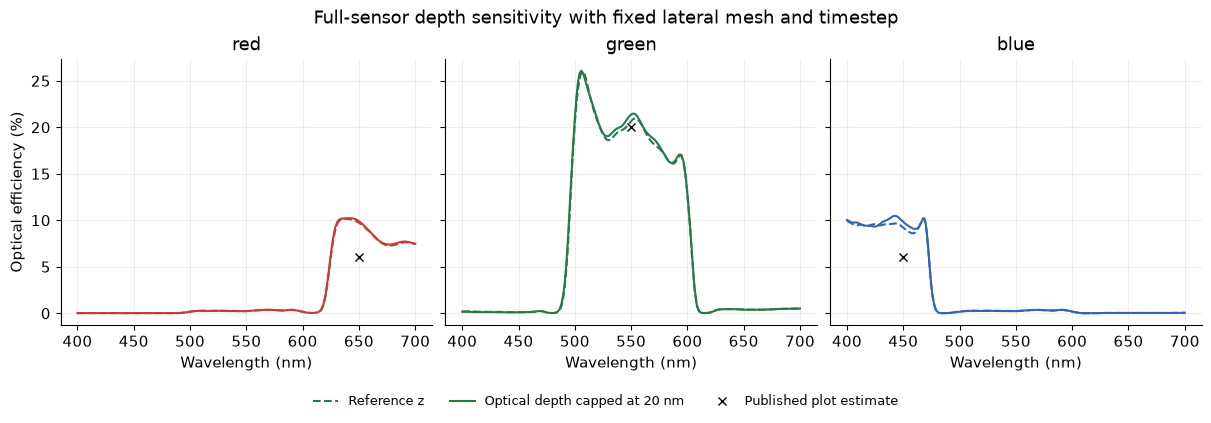

| Channel | Original z, central OE | Refined z, central OE | Max spectral change (pp) |
|---|---|---|---|
| red | 9.725% | 9.898% | 0.297 |
| green | 20.652% | 21.365% | 0.807 |
| blue | 9.203% | 9.807% | 0.815 |

Maximum late-time change in refined sensor (pp): 0.01392957745367518


In [6]:
baseline=np.load(evidence/"components/full/calibrated_efficiency.npz")
refined=np.load(evidence/"components/full-dz20nm/calibrated_efficiency.npz")
a=read_report(evidence/"components/full/report.json")
b=read_report(evidence/"components/full-dz20nm/report.json")
assert a["dt"]==b["dt"] and a["steps"]==b["steps"]
assert a["grid"][:2]==b["grid"][:2]
fig,axes=plt.subplots(1,3,figsize=(12,3.7),sharey=True,constrained_layout=True)
rows=[]
for ax,(channel,color) in zip(axes,colors.items()):
    ax.plot(wl[order],100*baseline[channel][order],"--",color=color,label="Reference z")
    ax.plot(wl[order],100*refined[channel][order],"-",color=color,label="Optical depth capped at 20 nm")
    ax.plot(central[channel],20 if channel=="green" else 6,"kx",label="Published plot estimate")
    ax.set(title=channel,xlabel="Wavelength (nm)");ax.grid(alpha=.2)
    rows.append((channel,f"{a['central_efficiency_percent'][channel]:.3f}%",f"{b['central_efficiency_percent'][channel]:.3f}%",f"{100*np.max(abs(refined[channel]-baseline[channel])):.3f}"))
axes[0].set_ylabel("Optical efficiency (%)");fig.legend(*axes[1].get_legend_handles_labels(),loc="upper center",bbox_to_anchor=(.5,-.02),ncol=3,frameon=False,fontsize=9)
fig.suptitle("Full-sensor depth sensitivity with fixed lateral mesh and timestep")
fig.savefig(evidence/"sensor_depth_control.png",dpi=150,bbox_inches="tight");plt.show()
show_table(["Channel","Original z, central OE","Refined z, central OE","Max spectral change (pp)"],rows)
print("Maximum late-time change in refined sensor (pp):",max(b["temporal_max_change_pp"].values()))

## Additional exclusions and accuracy checks

A smaller timestep on the original planar z mesh separates time discretization from depth refinement. CPML versus absorber checks boundary sensitivity in the planar geometry. A 100 nm aluminum-film control checks the imported metal against transfer matrices over 400–700 nm; it does not test the complete patterned shield.

In [7]:
time_control=read_report(evidence/"planar/absorber-courant-0.35/report.json")["runs"]
boundary_control=read_report(evidence/"planar/cpml/report.json")["runs"]
depth_control=read_report(evidence/"planar/absorber-dz20nm/report.json")["runs"]
rows=[]
for channel in colors:
    base=np.load(evidence/f"planar/absorber/{channel}-refine1.npz")
    reduced_dt=np.load(evidence/f"planar/absorber-courant-0.35/{channel}-refine1.npz")
    cpml=np.load(evidence/f"planar/cpml/{channel}-refine1.npz")
    depth=next(r for r in depth_control if r["channel"]==channel)
    rows.append((channel,f"{100*np.max(abs(reduced_dt['one_sided']-base['one_sided'])):.3f}",f"{100*np.max(abs(cpml['one_sided']-base['one_sided'])):.3f}",f"{depth['T_error_pp']['one_sided']:.3f}"))
show_table(["Planar channel","Smaller-dt change (pp)","Boundary change (pp)","Capped-depth T error vs exact (pp)"],rows)
metal=read_report(evidence/"metal-film/report.json")["runs"]
show_table(["Al film spacing","Max R error (pp)","Max T error (pp)"],[(f"{r['dx_nm']:g} nm",f"{r['R_error_pp']:.4f}",f"{r['T_error_pp']:.6f}") for r in metal])
reconstruction=read_report(evidence/"reconstruction/report.json")
rows=[(f"{r['shift']:g} cell",f"{r['T_max_error_pp']['linear']:.3f}",f"{r['T_max_error_pp']['compiled_plus']:.3f}") for r in reconstruction if r["dx_nm"]==2.5]
show_table(["Silicon interface shift, 2.5 nm grid","Linear T error (pp)","One-sided T error (pp)"],rows)

| Planar channel | Smaller-dt change (pp) | Boundary change (pp) | Capped-depth T error vs exact (pp) |
|---|---|---|---|
| red | 0.342 | 0.180 | 3.713 |
| green | 0.509 | 0.040 | 7.157 |
| blue | 0.650 | 0.019 | 9.367 |

| Al film spacing | Max R error (pp) | Max T error (pp) |
|---|---|---|
| 10 nm | 2.6037 | 0.000001 |
| 5 nm | 0.9334 | 0.000000 |
| 2.5 nm | 0.2502 | 0.000000 |

| Silicon interface shift, 2.5 nm grid | Linear T error (pp) | One-sided T error (pp) |
|---|---|---|
| 0 cell | 1.750 | 0.439 |
| 0.25 cell | 1.436 | 0.408 |
| 0.5 cell | 0.327 | 0.327 |

## Takeaways

- Integer-step timing fixes a demonstrated DFT defect. The finer planar controls recover convergence rather than worsening with longer step counts.
- Native incident calibration removes a coarse-grid denominator bias. One-sided H sampling removes cross-interface interpolation while keeping the detector physically fixed.
- The coarse planar stack still has appreciable spatial error; dielectric optical thickness and the SiN/silicon boundary require depth-convergence checks, not only finer metal cells or more wavelength samples.
- At fixed timestep, the targeted optical-depth refinement changes spectra by up to 0.297/0.807/0.815 percentage points and moves central values farther from the published plot. Lateral resolution, complete depth convergence and differing interface operators still require matched tests.
- Material coefficients already match the imported snapshot. The corrected sensor still needs matched numerical Tidy3D outputs and a full-sensor spatial-convergence study before attributing or claiming closure of the remaining gap. More run time alone is not supported as the main explanation by the late-time checks above.

The raw arrays, implementation changes, limitations, and repeat commands are documented in [the evidence report](../../docs/reviews/cmos-isolation/README.md).